# Positional Encoding

Embedding 값에 위치 정보를 추가하는 용도로 사용됨.

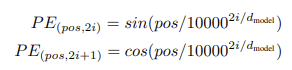

In [ ]:
import torch
import torch.nn as nn
import math

# Positional Encoding 그대로 수학 구현
# d_model은 emb_dim을 의미.
# max_len은 Positional Encoding이 처리할 수 있는 최대 token 수를 의미.
# 즉, default에서는 512개가 넘는 단어가 들어오면 오류가 남 ex (1, 513, 128) -> Error
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0)) # [1, max_len, d_model]

    def forward(self, x):
        T = x.size(1)

        return x + self.pe[:, :T] # 임베딩에 그대로 더하기

In [5]:
pos_enc = PositionalEncoding(d_model=16)

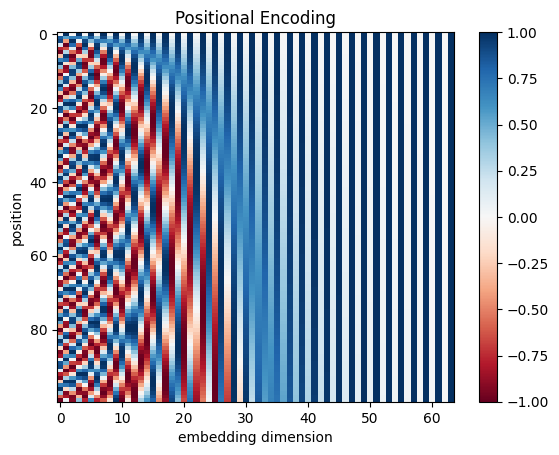

In [7]:
import matplotlib.pyplot as plt

pe = PositionalEncoding(d_model=64, max_len=100)
plt.imshow(pe.pe[0, :100, :64].numpy(), cmap="RdBu", aspect="auto")
plt.xlabel("embedding dimension"); plt.ylabel("position")
plt.title("Positional Encoding"); plt.colorbar(); plt.show()

### Embedding + Positional Encoding

In [22]:
emb_layer = nn.Embedding(100, embedding_dim=128)
pe = PositionalEncoding(d_model=128, max_len=100)

x = torch.tensor([[2, 3, 2, 5, 6, 8, 0, 0, 0, 0]])
x = emb_layer(x)
print("##### Embedding 결과 값: #####")
print(x.shape)
print(x)
print()

x = pe(x)
print("##### Positional Encoding 결과 값: #####")
print(x.shape)
print(x)

##### Embedding 결과 값: #####
torch.Size([1, 10, 128])
tensor([[[ 0.6734, -0.9199, -0.4389,  ...,  0.5224,  1.9108,  0.0657],
         [ 3.3468, -0.3630, -0.4379,  ..., -0.5591,  1.9964,  0.3901],
         [ 0.6734, -0.9199, -0.4389,  ...,  0.5224,  1.9108,  0.0657],
         ...,
         [-0.5819, -0.5897, -0.4549,  ...,  0.9084,  1.2861,  0.0209],
         [-0.5819, -0.5897, -0.4549,  ...,  0.9084,  1.2861,  0.0209],
         [-0.5819, -0.5897, -0.4549,  ...,  0.9084,  1.2861,  0.0209]]],
       grad_fn=<EmbeddingBackward0>)

##### Positional Encoding 결과 값: #####
torch.Size([1, 10, 128])
tensor([[[ 0.6734,  0.0801, -0.4389,  ...,  1.5224,  1.9108,  1.0657],
         [ 4.1882,  0.1773,  0.3238,  ...,  0.4409,  1.9965,  1.3901],
         [ 1.5827, -1.3360,  0.5481,  ...,  1.5224,  1.9111,  1.0657],
         ...,
         [ 0.0751,  0.1642, -0.6745,  ...,  1.9084,  1.2870,  1.0209],
         [ 0.4074, -0.7352,  0.1459,  ...,  1.9084,  1.2871,  1.0209],
         [-0.1698, -1.5009,  0.5433

# MultiHead Attention

Self Attention은 단어들 간의 상관관계를 볼 수 있게 해준다.<br/>
MultiHead Attention은 단일 어텐션이 놓칠 수 있는 다양한 관점의 문맥과 관계를 병렬로 학습하여 모델의 표현력을 높이기 위해 사용된다.

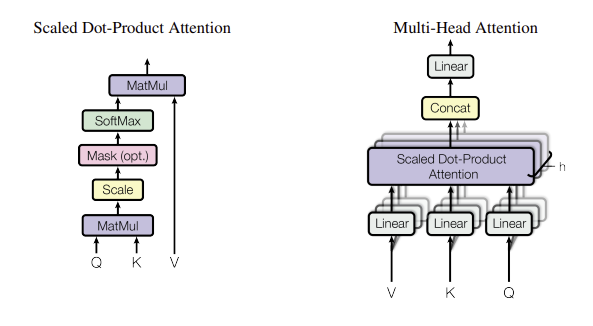

이전에 공부한 Scaled Dot-Product 연산을 여러개의 헤드로 나누어 구한다고 볼 수 있다.

**사실상, MultiHead Attention이 단일 Attention의 업그레이드 버전이라고 볼 수 있다.**

In [21]:
# 들어오는 Q, K, V는 W_q, W_k, W_v와 Embedding 결과 값을 각각 계산한 값.
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    output = weights @ V
    
    return output, weights

# MultiHead Attention Layer 구현
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0
        self.h = num_heads
        self.d_k = d_model // num_heads
        
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        # Sequence Length = Time Step이라고도 부릅니다. 
        # 이에 len이 아닌 T로 변수명을 지정.
        B, T, _ = x.shape

        # 기존 Embedding 값의 차원을 (h, k)로 바꿔줌.
        # d_model -> (h, k): 따라서 h x k = d_model임.
        x = x.view(B, T, self.h, self.d_k)

        return x.transpose(1, 2) # [B, h, T, d_k]

    def forward(self, x, mask=None):
        B, T, _ = x.shape
        Q = self.split_heads(self.W_q(x)) # [B, h, T, d_k]
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))

        # Q, K, V에 대해 scaled_dot_product_attention 적용
        # 여기서는 각 Head끼리 계산 수행.
        out, weights = scaled_dot_product_attention(Q, K, V, mask)

        # out: [B, h, T, d_k] → 다시 [B, T, d_model]로 합치기
        # 결국 MultiHead Attention을 거쳐도 Self-Attention과 마찬가지로 같은 결과가 나옴.
        out = out.transpose(1, 2).contiguous().view(B, T, -1)

        return self.W_o(out)

# FULL Code

Raw Data -> Tokenizer -> Padding or Truncate -> Embedding + **Positional Encoding** -> **MultiHead Attention**

In [40]:
# 예시로 감정 분류 모델을 조금 더 확장시켜보면 아래와 같아짐.
class TSModel(nn.Module):
    def __init__(self, vocab_size=50000, embed_dim=128, num_classes=2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

        # Embedding
        self.embed_layer = nn.Embedding(vocab_size, embed_dim)

        # 🍏🍏
        # Positional Encoding
        self.pe_layer = PositionalEncoding(d_model=embed_dim)

        # 🍏🍏
        # MultiHead Attention
        # 어차피 결과값은 Embedding + Positional Encoding을 거친 값과 동일.
        self.mul_att = MultiHeadAttention(embed_dim, num_heads=8)

        # 감정 분류(클래스가 2개)이므로 마지막 feed forward만 넣어주면 우리가 원하는 모델을 만들 수 있음.
        self.feed_forward = nn.Linear(embed_dim, num_classes)

        # softmax
        self.act = nn.Softmax(dim=-1)

    def forward(self, x):
        # Embedding
        embeded_x = self.embed_layer(x)

        # 🍏🍏
        # Positional Encoding
        pe_embeded_x = self.pe_layer(embeded_x)
        print(pe_embeded_x.shape)

        # 🍏🍏
        # MultiHead Attention
        output = self.mul_att(pe_embeded_x)
        print(output.shape)

        pooled = output.mean(dim=1)
        print(pooled.shape)

        # 긍정인지 부정인지 확인
        x = self.feed_forward(pooled)
        print(x.shape)
        
        # 확률값으로 변환
        x = self.act(x)

        return x

In [47]:
ts_model = TSModel()

In [48]:
x = torch.tensor([[1, 2, 3, 4]])
probas = ts_model(x)
print(probas)

torch.Size([1, 4, 128])
torch.Size([1, 4, 128])
torch.Size([1, 128])
torch.Size([1, 2])
tensor([[0.4388, 0.5612]], grad_fn=<SoftmaxBackward0>)
